<a href="https://colab.research.google.com/github/RaczNikoletta/Artificial-intelligence/blob/main/PE_SupervisedML/beadando.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breast Cancer Diagnosis using Machine Learning

A projekt célja a daganatok jóindulatú (benign) és rosszindulatú (malignant) osztályozása különböző sejtmorfológiai jellemzők alapján.

Könyvtárak importálása

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from pandas.plotting import parallel_coordinates

from sklearn.decomposition import PCA

from sklearn.datasets import load_breast_cancer

Dataset betöltése

In [ ]:
cancer = load_breast_cancer()

X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

y = pd.Series(cancer.target)

df = X.copy()
df["target"] = y

# Címkék átnevezése
df["diagnosis"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


EDA

In [ ]:
df.info()

df.describe()

print(df.columns.tolist())
duplicates = df.duplicated().sum()

print(f"Number of duplicate records: {duplicates}")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

Minden oszlopnál non null látható tehát minden rekord rendelkezik értékkel és nincs hiányzó adat, nincs duplikáció. Nincs szükség imputációra vagy rekordok eltávolítására

Adattípusok:
Minden változó float64
Nincs szükség kategóriaváltozók átalakítására

Célváltozó megoszlásának vizsgálata

/tmp/ipykernel_1161/3787793425.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


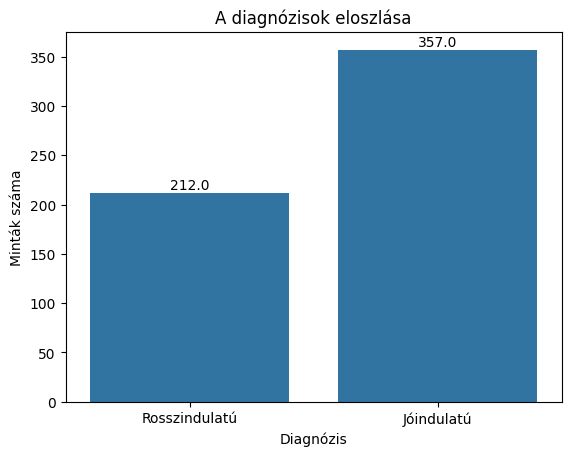

In [ ]:
ax = sns.countplot(x=df["target"])

ax.set_xticklabels(
    ["Rosszindulatú", "Jóindulatú"]
)

for p in ax.patches:
    ax.annotate(
        str(p.get_height()),
        (p.get_x() + p.get_width()/2,
         p.get_height()),
        ha="center",
        va="bottom"
    )

plt.xlabel("Diagnózis")
plt.ylabel("Minták száma")
plt.title("A diagnózisok eloszlása")

plt.show()

A célváltozó eloszlása mérsékelten kiegyensúlyozatlan. A jóindulatú daganatok száma magasabb, azonban az eltérés nem olyan jelentős, hogy speciális kiegyensúlyozó technikák (pl. SMOTE) alkalmazását indokolná.

Miben különböznek a jó- és rosszindulatú daganatok?

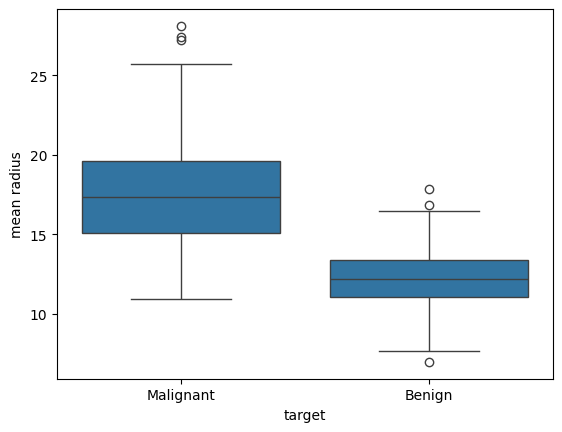

In [ ]:
sns.boxplot(
    x="target",
    y="mean radius",
    data=df
)

plt.xticks(
    [0,1],
    ["Malignant","Benign"]
)

plt.show()

Area

<Axes: xlabel='target', ylabel='mean area'>

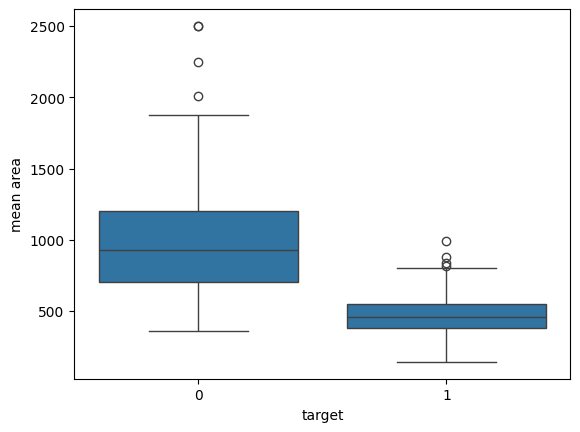

In [ ]:
sns.boxplot(
    x="target",
    y="mean area",
    data=df
)

sns.boxplot(
    x="target",
    y="mean perimeter",
    data=df
)

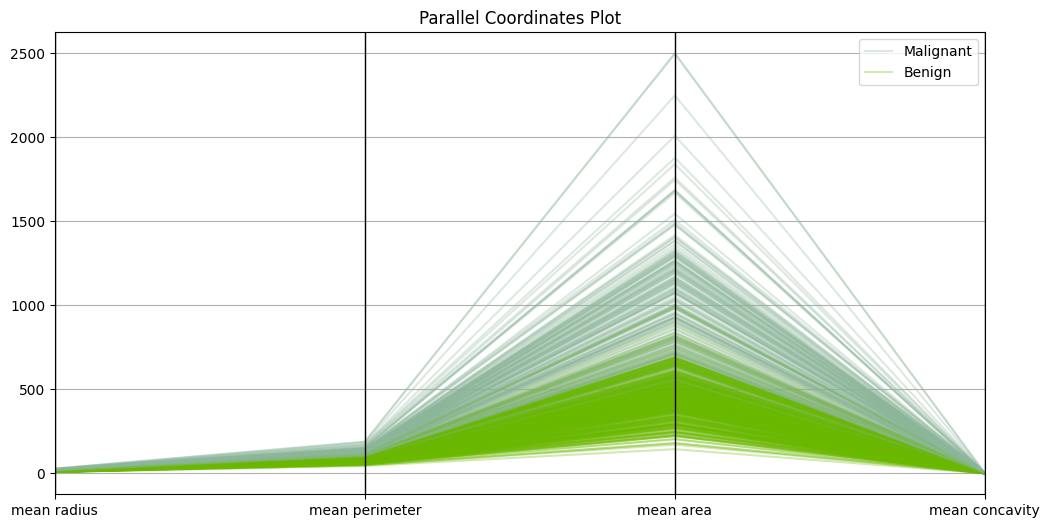

In [ ]:


features = [
    "target",
    "mean radius",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

plot_df = df[features].copy()

plot_df["target"] = plot_df["target"].map({
    0: "Malignant",
    1: "Benign"
})

plt.figure(figsize=(12,6))

parallel_coordinates(
    plot_df,
    class_column="target",
    alpha=0.3
)

plt.title("Parallel Coordinates Plot")
plt.show()

A mean area nagyságrendekkel nagyobb mint a többi változó, nézzük meg standardizálással az értékeket.

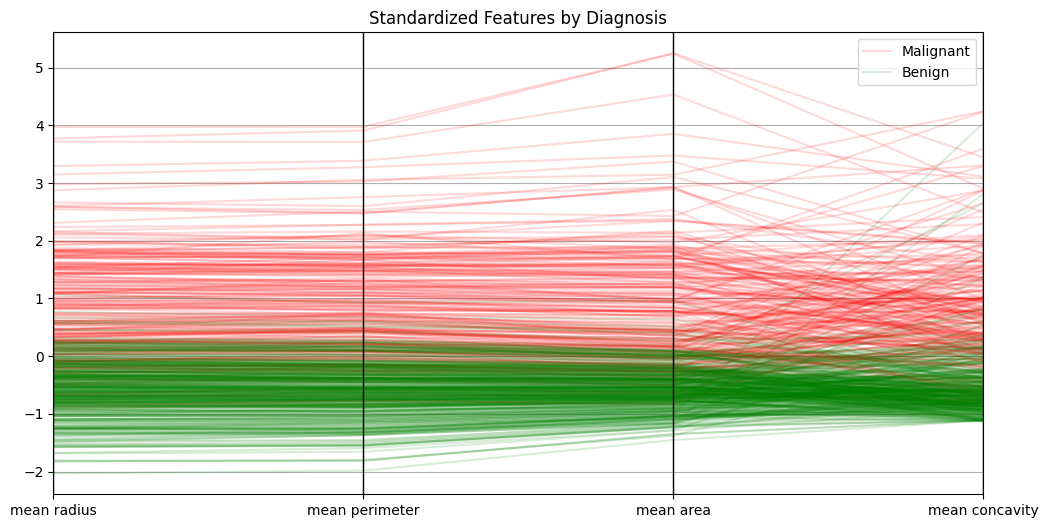

In [ ]:
features = [
    "mean radius",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

scaled = StandardScaler().fit_transform(df[features])

plot_df = pd.DataFrame(
    scaled,
    columns=features
)

plot_df["target"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})

plt.figure(figsize=(12,6))

parallel_coordinates(
    plot_df,
    "target",
    color=["red", "green"],
    alpha=0.15
)

plt.title("Standardized Features by Diagnosis")

plt.show()

Nem az igazi, nézzük meg PCA-val

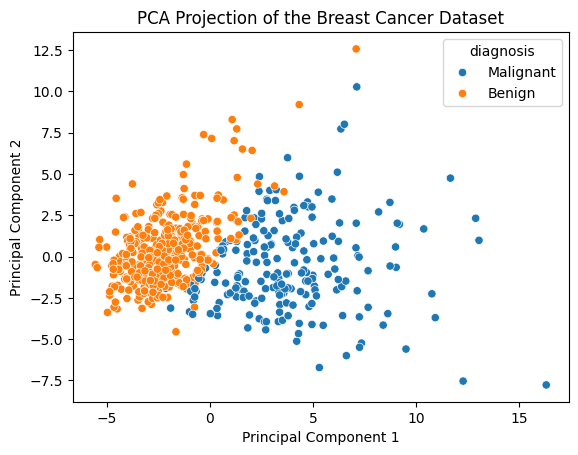

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pc1 = X_pca[:, 0]
pc2 = X_pca[:, 1]

sns.scatterplot(
    x=pc1,
    y=pc2,
    hue=df["diagnosis"]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of the Breast Cancer Dataset")

plt.show()